# RAG Part 1, Experiment 4: does retrieval work on questions?

Expts 1–3 tuned retrieval on **claims** ("DBMF's expense ratio is 0.85%"). The product answers **questions**
("What is DBMF's expense ratio?"), which are shorter and leave the figure out. This notebook re-checks two things:

1. **Retrieval:** are the right excerpts among the 5 the LLM sees?
2. **The gate:** if the reranker's best score is below 0.20, the pipeline answers "not in corpus" without calling the
   LLM. Does that threshold still make sense for questions?

**Result in one line:** three fixes made retrieval much better (findings 1–2), diversity rules did not help (finding 3),
and the gate only catches questions about things the corpus never mentions (finding 4). Everything subtler is the
answer prompt's job.

### Words used below

| term | meaning |
|---|---|
| chunk | one passage of an article (17,045 in total) |
| dense search | meaning-based search with the `all-mpnet-base-v2` embeddings, via Chroma |
| BM25 | keyword search: exact word and number matches ("BLNDX", "1.27") |
| pool | the candidate chunks handed to the reranker |
| reranker | `bge-reranker-base`: re-scores each (question, chunk) pair 0–1; the top 5 go to the LLM |
| **hit@5** | share of questions with a correct chunk in the top 5 (the main number) |
| MRR | how high the first correct chunk ranks (1 = always first, 0.5 = typically second) |
| gate | top reranker score < 0.20 → "not in corpus", no LLM call |

> **Experimental.** The questions were written by an LLM (Claude Haiku 5.5) and will be rebuilt with another model.
> Small groups (15 synthesis, 2 conflict, 19 not-in-corpus test questions) give rough rates.

In [1]:
import os
import sys

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # models are cached; skip the Hub check
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
sys.path.insert(0, "..")

import time
from pathlib import Path

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer

from alpha_audit.config import get_settings
from alpha_audit.retrieval import rerank_input, select
from alpha_audit.retrieval.retriever import bm25_tokens
from eval.common import K, auroc, fetch, load_goldset, score_item

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

S = get_settings().retrieval
CHROMA_PATH, DATA_DIR, QA_SET = "../.chroma", "../data/processed", "../eval/qa_goldset.jsonl"
CE_CACHE = Path(DATA_DIR) / "expt4_ce_cache.csv.gz"  # reranker scores per (question, chunk), so re-runs are fast
GATE = S.not_in_corpus_threshold  # 0.20
SINGLE, MULTI = ["fact", "false_premise", "faq"], ["synthesis", "conflict"]
ANSWERABLE = SINGLE + MULTI
ORDER = [*ANSWERABLE, "not_in_corpus", "advice"]

/Users/zhaoweikennethlim/Desktop/fin-audit-guard-rag/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The questions

305 questions from `eval/qa_goldset.jsonl`. Each answerable question lists its correct chunks.

| category | what a good retrieval looks like |
|---|---|
| `fact`, `false_premise`, `faq` | the chunk stating the fact is in the top 5 (one article) |
| `synthesis`, `conflict` | chunks from **both** articles are in the top 5 |
| `not_in_corpus` | nothing relevant exists, so the top score should be low and the gate should refuse |
| `advice` | ("Should I buy X?") not scored for retrieval |

In [2]:
items = load_goldset(QA_SET)
chunks = pd.read_csv(f"{DATA_DIR}/chunks_B_structured_clean.csv", keep_default_na=False).set_index("chunk_id")
for it in items:  # the articles that hold a correct chunk (two for synthesis / conflict)
    it["gold_docs"] = sorted({chunks.at[c, "doc_id"] for c, g in it["gold_chunk_ids"].items() if g == 2})
by_qid = {it["qid"]: it for it in items}
qa = pd.DataFrame(items)
pd.crosstab(qa.category, qa.split, margins=True).reindex([*ORDER, "All"])

split,dev,test,All
category,,,
fact,42,43,85
false_premise,25,25,50
faq,37,63,100
synthesis,8,7,15
conflict,1,1,2
not_in_corpus,19,19,38
advice,8,7,15
All,140,165,305


## Finding 1: the search index was losing results (fixed)

Chroma's search is *approximate*: it explores only part of the index, set by `ef_search`. At the old value of 100
it sometimes missed chunks it should have found. "What is DBMF's expense ratio?" lost the DBMF review that way, scored
0.014 and was wrongly refused.

**Fix:** `ef_search` raised to 500 on the collection. Check below: compare Chroma's top 50 with the *exact* top 50
(every chunk scored with numpy). At 100 the average overlap was 96% and the worst question got 64%.

In [3]:
model = SentenceTransformer(S.embedding_model)
col = chromadb.PersistentClient(path=CHROMA_PATH).get_collection(S.collection)
print("ef_search now:", col.configuration_json["hnsw"]["ef_search"])

everything = col.get(include=["embeddings"])
CHUNK_IDS = np.array(everything["ids"])
EMB = dict(zip(CHUNK_IDS, np.asarray(everything["embeddings"], dtype=np.float32)))
ALL_EMBS = np.stack([EMB[c] for c in CHUNK_IDS])

questions = [it["question"] for it in items]
Q_EMBS = model.encode(questions, normalize_embeddings=True, batch_size=64)
DENSE = [r for i in range(0, len(Q_EMBS), 20)  # dense top 200 per question (batches: SQLite variable limit)
         for r in fetch(col, Q_EMBS[i:i + 20], k_fetch=200)]

exact = np.argsort(-(Q_EMBS @ ALL_EMBS.T), axis=1)[:, :50]
overlap = np.array([len(set(CHUNK_IDS[e]) & {c["chunk_id"] for c in d[:50]}) / 50 for e, d in zip(exact, DENSE)])
print(f"Chroma top 50 vs exact top 50: mean overlap {overlap.mean():.1%}, worst question {overlap.min():.0%}")

ef_search now: 500


Chroma top 50 vs exact top 50: mean overlap 99.8%, worst question 94%


## Finding 2: adding keyword search gave the biggest improvement (applied)

Questions hinge on tickers and figures. Dense search blurs them ("BLNDX" and "BTAL" look alike to it); BM25 matches them
exactly. Four pools compared, all reranked the same way:

- **old:** dense top 50 → reranker
- **bigger dense pool:** dense top 200 → reranker (does simply fetching more help?)
- **new:** dense top 50 + BM25 top 50 → reranker
- dense top 50 without the reranker, for reference

`correct chunk in pool` = the reranker had a chance to find it. The reranker cannot rescue a chunk that is not in the
pool.

In [4]:
bm25 = BM25Okapi([bm25_tokens(s) for s in chunks.embed_text])
CE = {(q, c): s for q, c, s in pd.read_csv(CE_CACHE).itertuples(index=False)} if CE_CACHE.exists() else {}
reranker = CrossEncoder(S.reranker, max_length=512)


def build_pools(questions, q_embs, dense):
    # Per question: dense top 200 + BM25 top 50, each chunk tagged with its rank in each list and its reranker score.
    pools = []
    for q, q_emb, dcs in zip(questions, q_embs, dense):
        pool = {c["chunk_id"]: {**c, "dense_rank": r, "bm25_rank": None} for r, c in enumerate(dcs)}
        for r, cid in enumerate(CHUNK_IDS[np.argsort(-bm25.get_scores(bm25_tokens(q)))[:50]]):
            if cid not in pool:
                row = chunks.loc[cid]
                pool[cid] = {"chunk_id": cid, "doc_id": row.doc_id, "title": row.title, "section": row.section,
                             "text": row.text, "sim": float(EMB[cid] @ q_emb), "dense_rank": None}
            pool[cid]["bm25_rank"] = r
        pools.append(list(pool.values()))
    todo = list(dict.fromkeys((q, c["chunk_id"]) for q, p in zip(questions, pools) for c in p if (q, c["chunk_id"]) not in CE))
    if todo:
        text = {c["chunk_id"]: rerank_input(c) for p in pools for c in p}
        CE.update(zip(todo, map(float, reranker.predict([(q, text[c]) for q, c in todo], batch_size=64))))
        pd.DataFrame([(q, c, s) for (q, c), s in CE.items()], columns=["query", "chunk_id", "ce"]).to_csv(CE_CACHE, index=False)
    for q, p in zip(questions, pools):
        for c in p:
            c["ce"] = CE[(q, c["chunk_id"])]
    return pools


POOLS = build_pools(questions, Q_EMBS, DENSE)

CONFIGS = {  # name -> (dense top n, BM25 top n, use reranker)
    "dense 50, no reranker": (50, 0, False),
    "old: dense 50 → reranker": (50, 0, True),
    "dense 200 → reranker": (200, 0, True),
    "new: dense 50 + BM25 50 → reranker": (50, 50, True),
}
OLD, NEW = "old: dense 50 → reranker", "new: dense 50 + BM25 50 → reranker"


def ranked(pool, n_dense, n_bm25, rerank):
    sub = [c for c in pool if (c["dense_rank"] is not None and c["dense_rank"] < n_dense)
           or (c["bm25_rank"] is not None and c["bm25_rank"] < n_bm25)]
    return sorted(sub, key=lambda c: c["ce"] if rerank else c["sim"], reverse=True)


def is_correct(it, c):
    return it["gold_chunk_ids"].get(c["chunk_id"], 0) == 2


def both_articles(it, top):
    return {c["doc_id"] for c in top if is_correct(it, c)} >= set(it["gold_docs"])


sample = [(questions[i], rerank_input(c)) for i in range(8) for c in POOLS[i][:40]]
t = time.time()
reranker.predict(sample, batch_size=64)
PAIRS_PER_S = len(sample) / (time.time() - t)

rows = []
for name, spec in CONFIGS.items():
    for it, pool in zip(items, POOLS):
        r = ranked(pool, *spec)
        row = {"config": name, "qid": it["qid"], "category": it["category"], "split": it["split"],
               "top1": r[0]["ce" if spec[2] else "sim"], "pairs": len(r) if spec[2] else 0,
               "top_chunk_ids": [c["chunk_id"] for c in r[:10]]}
        if it["gold_chunk_ids"]:
            row |= score_item(r[:10], it, ks=(1, 5, 10))
            row["in pool"] = float(any(is_correct(it, c) for c in r))
            row["both articles@5"] = float(both_articles(it, r[:K]))
        rows.append(row)
per_item = pd.DataFrame(rows)
per_item["config"] = pd.Categorical(per_item.config, list(CONFIGS), ordered=True)
ans = per_item[per_item.category.isin(ANSWERABLE)]

overall = ans.groupby("config", observed=True).agg(
    **{"correct chunk in pool": ("in pool", "mean"), "hit@5": ("hit@5", "mean"), "MRR": ("rr", "mean")})
overall["both articles in top 5 (17 two-article qs)"] = (
    ans[ans.category.isin(MULTI)].groupby("config", observed=True)["both articles@5"].sum().astype(int).astype(str) + " / 17")
overall["seconds / question"] = (ans.groupby("config", observed=True).pairs.mean() / PAIRS_PER_S).round(1)
print(f"{len(items) - len(ans) // len(CONFIGS)} unanswerable questions excluded; {len(ans) // len(CONFIGS)} answerable. "
      f"Reranker speed on this machine: {PAIRS_PER_S:.0f} pairs/s")
overall.round(3)

53 unanswerable questions excluded; 252 answerable. Reranker speed on this machine: 56 pairs/s


,correct chunk in pool,hit@5,MRR,both articles in top 5 (17 two-article qs),seconds / question
config,,,,,
"dense 50, no reranker",0.877,0.635,0.506,0 / 17,0.0
old: dense 50 → reranker,0.877,0.845,0.717,2 / 17,0.9
dense 200 → reranker,0.933,0.865,0.738,5 / 17,3.6
new: dense 50 + BM25 50 → reranker,0.988,0.929,0.788,5 / 17,1.4


hit@5 by question type. BM25 helps most where the question names a ticker or a figure (`fact`, `false_premise`).

In [5]:
ans.groupby(["config", "category"], observed=True)["hit@5"].mean().unstack()[ANSWERABLE].round(2)

category,fact,false_premise,faq,synthesis,conflict
config,,,,,
"dense 50, no reranker",0.64,0.72,0.67,0.13,0.5
old: dense 50 → reranker,0.82,0.84,0.88,0.73,1.0
dense 200 → reranker,0.85,0.88,0.89,0.73,1.0
new: dense 50 + BM25 50 → reranker,0.94,0.98,0.90,0.87,1.0


## Finding 3: forcing variety among the top 5 made things worse (no change)

Synthesis and conflict questions need chunks from **two** articles. Two common tricks to get more articles into the top
5, tried on the new pool:

- **cap 2 per article:** at most 2 chunks from any one article
- **MMR:** penalise chunks that are similar to ones already picked (λ = 0.8 keeps most weight on the reranker score)

In [6]:
def mmr(cands, k=K, lam=0.8):
    chosen, rest = [], list(cands[:50])
    while rest and len(chosen) < k:
        best = max(rest, key=lambda c: lam * c["ce"] - (1 - lam) * max(
            (float(EMB[c["chunk_id"]] @ EMB[x["chunk_id"]]) for x in chosen), default=0.0))
        chosen.append(best)
        rest.remove(best)
    return chosen


SELECTORS = {"plain top 5 (kept)": lambda cs: select(cs, k=K),
             "cap 2 per article": lambda cs: select(cs, k=K, per_doc_cap=2),
             "MMR λ=0.8": mmr}
rows = []
for name, pick in SELECTORS.items():
    for it, pool in zip(items, POOLS):
        if it["category"] in ANSWERABLE:
            top = pick(ranked(pool, *CONFIGS[NEW]))
            rows.append({"selector": name, "multi": it["category"] in MULTI,
                         "hit": any(is_correct(it, c) for c in top), "both": both_articles(it, top)})
sel = pd.DataFrame(rows)
selection = pd.DataFrame({
    "hit@5, one-article questions": sel[~sel.multi].groupby("selector", sort=False).hit.mean().round(3),
    "hit@5, two-article questions": sel[sel.multi].groupby("selector", sort=False).hit.mean().round(3),
    "both articles in top 5": sel[sel.multi].groupby("selector", sort=False).both.sum().astype(str) + " / 17",
})
selection

,"hit@5, one-article questions","hit@5, two-article questions",both articles in top 5
selector,,,
plain top 5 (kept),0.932,0.882,5 / 17
cap 2 per article,0.911,0.765,3 / 17
MMR λ=0.8,0.902,0.824,5 / 17


Both tricks lower hit@5 and do not get the second article in more often. The second article's chunk is simply ranked
below several chunks of the first, and a cap cannot fix a ranking. The likely fix is **one search per entity**
(split "A vs B" into a search for A and one for B). That is deferred until after answer prompt v1.

## Finding 4: the gate catches missing funds, not missing figures (kept at 0.20)

Each question's **top-1 reranker score**, by type, on the new pool. The gate refuses everything left of the dashed line.

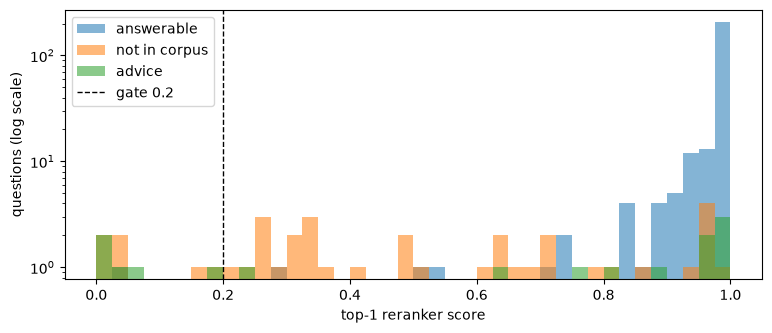

In [7]:
m = per_item[per_item.config == NEW]
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(0, 1, 41)
for cats, label in [(ANSWERABLE, "answerable"), (["not_in_corpus"], "not in corpus"), (["advice"], "advice")]:
    ax.hist(m[m.category.isin(cats)].top1, bins=bins, alpha=0.55, label=label)
ax.axvline(GATE, color="k", ls="--", lw=1, label=f"gate {GATE}")
ax.set(xlabel="top-1 reranker score", ylabel="questions (log scale)", yscale="log")
ax.legend()
plt.show()

Most not-in-corpus questions score **high**: they ask for a figure the corpus never states, about a fund it *does*
discuss ("QSPIX's Sortino ratio"). The reranker sees "QSPIX" and scores the QSPIX review highly. The top ones:

In [8]:
neg = m[m.category == "not_in_corpus"].sort_values("top1", ascending=False)
print(f"not-in-corpus questions scoring above 0.9: {(neg.top1 > 0.9).sum()} of {len(neg)}\n")
for _, r in neg.head(6).iterrows():
    print(f"{r.top1:.2f}  {by_qid[r.qid]['question'][:80]}\n      top chunk: {chunks.at[r.top_chunk_ids[0], 'title'][:75]}")

not-in-corpus questions scoring above 0.9: 6 of 38

0.99  What was the Sortino ratio for the QSPIX fund?
      top chunk: AQR Style Premia Alternative Fund Review: QSPIX Mutual Fund Review
0.97  What Sortino ratio did the Vanguard Wellington Fund (VWELX) post?
      top chunk: 10 Ways Investors Can Improve The Ray Dalio All Weather Portfolio
0.96  What was the Sortino ratio reported for the SVOL fund?
      top chunk: Fidelity Contrafund FCNTX Review: Most Successful Actively Managed Mutual F
0.95  What was the Sortino ratio for the QMOM fund?
      top chunk: Trend Following & All Weather Investing with Eric Crittenden of Standpoint 
0.95  What Sortino ratio did NTSE post in the investing blog articles?
      top chunk: 10 Ways Investors Can Improve The Ray Dalio All Weather Portfolio
0.93  What was the Sortino ratio for the IMOM fund?
      top chunk: Trend Following & All Weather Investing with Eric Crittenden of Standpoint 


Could a stricter threshold catch them? Compare 0.20 with the "best balance" threshold picked on **dev** (Youden: the
cut that best separates answerable from not-in-corpus), both measured on **test**:

In [9]:
def youden(pos, neg):
    return max(np.unique(np.concatenate([pos, neg])), key=lambda t: (pos >= t).mean() - (neg >= t).mean())


def scores(split, cats):
    return m[(m.split == split) & m.category.isin(cats)].top1.to_numpy()


pos_t, neg_t, advice = scores("test", ANSWERABLE), scores("test", ["not_in_corpus"]), m[m.category == "advice"].top1
strict = youden(scores("dev", ANSWERABLE), scores("dev", ["not_in_corpus"]))
print(f"How well the top-1 score separates the two groups (AUROC, test): {auroc(pos_t, neg_t):.2f} (1 = perfectly)\n")
gate = pd.DataFrame([{"threshold": f"{thr:.2f}" + (" (kept)" if thr == GATE else " (strict, from dev)"),
                      "answerable questions wrongly refused": f"{(pos_t < thr).sum()} / {len(pos_t)}",
                      "not-in-corpus questions let through": f"{(neg_t >= thr).sum()} / {len(neg_t)}",
                      "advice questions refused (all splits)": f"{(advice < thr).sum()} / {len(advice)}"}
                     for thr in (GATE, strict)]).set_index("threshold")
gate

How well the top-1 score separates the two groups (AUROC, test): 0.96 (1 = perfectly)



,answerable questions wrongly refused,not-in-corpus questions let through,advice questions refused (all splits)
threshold,,,
0.20 (kept),0 / 139,14 / 19,5 / 15
"0.97 (strict, from dev)",24 / 139,2 / 19,12 / 15


The strict threshold would refuse 24 of 139 (about 1 in 6) real questions, and a wrongly refused question has no way back. Letting a
not-in-corpus question through is cheaper: the LLM sees excerpts without the figure and can still say "not covered".
So **0.20 stays**, and the gate only stops questions about things the corpus never mentions.

Two side effects of the gate:
- **Advice:** some "Should I buy X for my retirement?" questions score low and get refused as "not in corpus". That is
  safe (no advice is given), and the harness counts it as correct (decision (b)).
- **Absurd premises** can score low too, because the chunk contradicts the question.

Probe questions on the old and new pools:

In [10]:
PROBES = ["What is DBMF's expense ratio?", "What's SCHD's expense ratio?", "Should I buy DBMF for my retirement account?",
          "Why is the annual fee on BLNDX 3.80%?", "All Weather vs Golden Butterfly: allocation and drawdown?"]
p_embs = model.encode(PROBES, normalize_embeddings=True)
probe_pools = build_pools(PROBES, p_embs, fetch(col, p_embs, k_fetch=200))
for q, pool in zip(PROBES, probe_pools):
    old, new = ranked(pool, *CONFIGS[OLD]), ranked(pool, *CONFIGS[NEW])
    verdict = "gated" if new[0]["ce"] < GATE else "to LLM"
    print(f"{q}\n   old top1 {old[0]['ce']:.2f} | new top1 {new[0]['ce']:.2f} ({verdict}): {new[0]['title'][:70]}")

What is DBMF's expense ratio?
   old top1 0.96 | new top1 0.97 (to LLM): What's The Best Managed Futures ETF? DBMF vs KMLM vs CTA
What's SCHD's expense ratio?
   old top1 0.13 | new top1 0.13 (gated): How To Invest Like Jack Bogle: Founder of Vanguard Group
Should I buy DBMF for my retirement account?
   old top1 0.02 | new top1 0.02 (gated): What's The Best Managed Futures ETF? DBMF vs KMLM vs CTA
Why is the annual fee on BLNDX 3.80%?
   old top1 0.04 | new top1 0.04 (gated): BLNDX / REMIX Review: The Strategy Behind Standpoint Multi-Asset Fund 
All Weather vs Golden Butterfly: allocation and drawdown?
   old top1 0.11 | new top1 0.23 (to LLM): Model Portfolios / Lazy Portfolios List


## Save

In [11]:
overall.to_csv(f"{DATA_DIR}/expt4_retrieval_overall.csv")
ans.groupby(["config", "category"], observed=True)[["in pool", "hit@1", "hit@5", "rr", "both articles@5"]].mean().round(3) \
    .to_csv(f"{DATA_DIR}/expt4_retrieval_by_category.csv")
selection.to_csv(f"{DATA_DIR}/expt4_selection.csv")
gate.to_csv(f"{DATA_DIR}/expt4_gate.csv")
per_item.drop(columns="top_chunk_ids").to_csv(f"{DATA_DIR}/expt4_per_item.csv", index=False)
print("saved expt4_*.csv to", DATA_DIR)

saved expt4_*.csv to ../data/processed


## Summary

| | what | status |
|---|---|---|
| 1 | Chroma `ef_search` 100 → 500: the index stops losing chunks | applied |
| 2 | BM25 top 50 added to the pool (`bm25_k: 50`): hit@5 0.85 → 0.93, correct chunk in pool 88% → 99%; 1.4 s instead of 0.9 s per question | applied |
| 3 | no per-article cap, no MMR: plain top 5 | kept |
| 4 | gate stays 0.20: refuses 0 of 139 answerable test questions, lets 14 of 19 not-in-corpus ones through | kept |

**Left for later:** one search per entity for "A vs B" questions (only 5 of 17 get both articles today).

**What this means for answer prompt v1.** The excerpts are better, but the gate only filters the obvious cases. The
prompt has to handle:
- a fund the excerpts cover, with the asked figure **missing** → say it is not covered (most not-in-corpus questions);
- **false premises** → correct them from the excerpts;
- **conflicts** between articles → report both values;
- **advice** → decline, then say what the articles cover.